# Projet Python
## Calcul scientifique: Optimisation et classification de données

Choisissez un problème de classification binaire :

- `main-pied` : `hand` vs `foot` ;
- `pingouin-perroquet` : `penguin` vs `parrot` ;
- `oignon-ananas` : `onion` vs `pineapple`.

La première classe porte l'étiquette $0$, la seconde l'étiquette $1$.

L'objectif est de programmer vous-mêmes une régression logistique, son gradient, une descente à pas fixe puis une recherche linéaire d'Armijo. `scikit-learn` ne sera utilisé comme classifieur qu'à la fin, pour comparaison.

Les données proviennent du **Quick, Draw! Dataset** de Google Creative Lab (licence CC BY 4.0). Les fonctions de téléchargement sont fournies.



In [31]:
# À exécuter UNE SEULE FOIS si PyQt5 n'est pas disponible :
%pip install -U PyQt5

# Dans Jupyter, cette commande intègre la boucle événementielle Qt au notebook.
# La fenêtre de dessin reste interactive sans bloquer l'exécution des cellules.
%gui qt5

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
## PACKAGES 

import json
import time
import urllib.parse
import urllib.request
from pathlib import Path
import importlib
import numpy as np
%gui qt5
import matplotlib.pyplot as plt
from PIL import Image

#from sklearn.model_selection import train_test_split
#from sklearn.metrics import (
#    accuracy_score, confusion_matrix, precision_score,
#    recall_score, log_loss
#)

import dessin_process 


importlib.reload(dessin_process)


# Même architecture que dans le TP2 :
# - dessin_process.py : calculs et traitements d'images ;
# - dessin_viewer.py  : interface graphique Qt.


RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)


### 1. Question préambule:
Commencez par classer intuitivement les trois couples du plus facile au plus difficile pour un humain. Vous reviendrez sur cette réponse à la fin du projet.

### 2.1 Choix du couple
choisissez l'un des couples via la variable $\texttt{PAIR}$. Chargez un nombre identique de dessins $\texttt{N\_PER\_CLASS}$ pour chaque classe. Puis créez un dictionnaire python via la variable $\texttt{PAIRS}$. Un dictionnaire permet d'associer à des clés des valeurs. Dans notre cas: Clé = "main-pied", "pingouin-perroquet" et "oignon-ananas". Valeurs =("hand", "foot", "main", "pied"),("penguin", "parrot", "pingouin", "perroquet") et ("onion", "pineapple", "oignon", "ananas").



Une image en niveaux de gris codée sur 8 bits par pixel utilise un octet par pixel. Chaque pixel est représenté par une valeur entière comprise entre 0 et 255. L’image peut alors être manipulée comme un tableau NumPy uint8 à deux dimensions : la première dimension correspond à la hauteur et la seconde à la largeur.

Complétez $\texttt{compute\_centering\_parameters}$ et $\texttt{image\_converter}$ du module $\texttt{dessin\_process}$ ainsi que les fonctions $\texttt{paint\_disk}$ et $\texttt{paint\_segment}$


In [33]:
## 1/ Choisissez votre problème ici

PAIR = "hand-foot"  # "main-pied", "pingouin-perroquet", "oignon-ananas"
N_PER_CLASS = 1200

PAIRS = {
    "hand-foot": ("hand", "foot", "main", "pied"),
    "penguin-parrot": ("penguin", "parrot", "penguin", "parrot"),
    "onion-pineapple": ("onion", "pineapple", "oignon", "ananas"),
}   

cat0, cat1, nom0, nom1 = PAIRS[PAIR]
print(f"Problème choisi : {nom0} (Étiquette 0) / {nom1} (Étiquette 1)")


Problème choisi : main (Étiquette 0) / pied (Étiquette 1)


#### Fonction $\texttt{paint\_disk}$

Le point `(x, y)` représente le centre du disque, avec `x` correspondant à la colonne et `y` à la ligne. Le disque est de rayon `radius`.
Un pixel de coordonnées `(i, j)` appartient au disque si


$(i-y)^2+(j-x)^2 \leq \texttt{radius}^2.$

Les pixels appartenant au disque devront recevoir la valeur `1` (=blanc).

#### Fonction $\texttt{paint\_segment}$

Les positions successives de la souris peuvent être relativement éloignées lorsque l'utilisateur dessine rapidement. Dessiner uniquement un disque à chaque position provoquerait alors des trous dans le trait.

Complétez la fonction ``` paint_segment(bitmap, p0, p1, radius)```

qui relie deux points $p_0=(x_0,y_0)
\quad\text{et}\quad
p_1=(x_1,y_1)$ par un trait continu.

Pour cela :

1. calculez la distance entre `p0` et `p1` ;
2. choisissez un nombre suffisant de points intermédiaires entre ces deux positions ;
3. utilisez `np.linspace` pour interpoler leurs coordonnées ;
4. appelez `paint_disk` en chacun de ces points.

Attention: Le pas entre deux centres successifs doit être suffisamment petit par rapport au rayon du pinceau pour que les disques se chevauchent et forment un trait continu.


In [34]:
from dessin_process import test_paint_disk ,test_paint_segment,image_converter

In [35]:
# =================================================================
# TÉLÉCHARGEMENT ET PRÉPARATION DES DONNÉES QUICKDRAW 
# =================================================================
#
# Les traitements d'image sont dans dessin_process.py :
#   - compute_centering_parameters(...)
#   - paint_disk(...)
#   - paint_segment(...)
#   - image_converter(...)
#

BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/"
CACHE_DIR = Path("quickdraw_cache")
CACHE_DIR.mkdir(exist_ok=True)


def load_quickdraw_category(category, n_samples=1200, force=False):
    """Charge ``n_samples`` dessins QuickDraw d'une catégorie.

    Les dessins vectoriels lus dans le fichier NDJSON sont convertis en
    bitmaps 28 x 28 par ``dessin_process.image_converter`` puis mis en cache.
    """
    cache = CACHE_DIR / f"{category}_{n_samples}.npy"
    print(cache)
    if cache.exists() and not force:
        return np.load(cache)

    url = BASE_URL + urllib.parse.quote(category) + ".ndjson"
    print(f"Téléchargement d'un sous-ensemble de '{category}' depuis QuickDraw ({n_samples} échantillons)...")

    images = []

    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            for line in response:
                record = json.loads(line.decode("utf-8"))

                # Conversion vectoriel -> bitmap assurée par dessin_process.py.
                images.append(image_converter(record["drawing"]))

                if len(images) >= n_samples:
                    break

    except Exception as exc:
        raise RuntimeError(
            "Impossible de télécharger QuickDraw. Vérifiez la connexion internet. "
            "Une fois les fichiers mis en cache, les séances suivantes peuvent "
            "être faites hors ligne."
        ) from exc

    arr = np.stack(images)
    np.save(cache, arr)
    return arr


def load_pair(pair=PAIR, n_per_class=N_PER_CLASS):
    """Charge les deux catégories correspondant au problème choisi."""
    c0, c1, n0, n1 = PAIRS[pair]

    A = load_quickdraw_category(c0, n_per_class)
    B = load_quickdraw_category(c1, n_per_class)

    Ximg = np.concatenate([A, B], axis=0)
    y = np.concatenate([
        np.zeros(len(A), dtype=int),
        np.ones(len(B), dtype=int)
    ])

    idx = rng.permutation(len(y))
    return Ximg[idx], y[idx], (n0, n1)

### 2.1 Choix du couple et chargement

Chargez les données.


In [36]:
# TODO — charger les données

Ximg, y, class_names = load_pair(PAIR, N_PER_CLASS)
print("Images :", Ximg.shape[0])
print("Etiquettes :", y.shape[0])
print("Effectifs :", N_PER_CLASS)
print("Classes :", class_names)
#y donne l'ettiquette de la classe Ximg[i]
#Ximg contient differents images de la classe choisi



quickdraw_cache\hand_1200.npy
quickdraw_cache\foot_1200.npy
Images : 2400
Etiquettes : 2400
Effectifs : 1200
Classes : ('main', 'pied')


### 2.2 Premières visualisations
Affichez au moins 16 dessins de chaque classe à l'aide de matplotlib

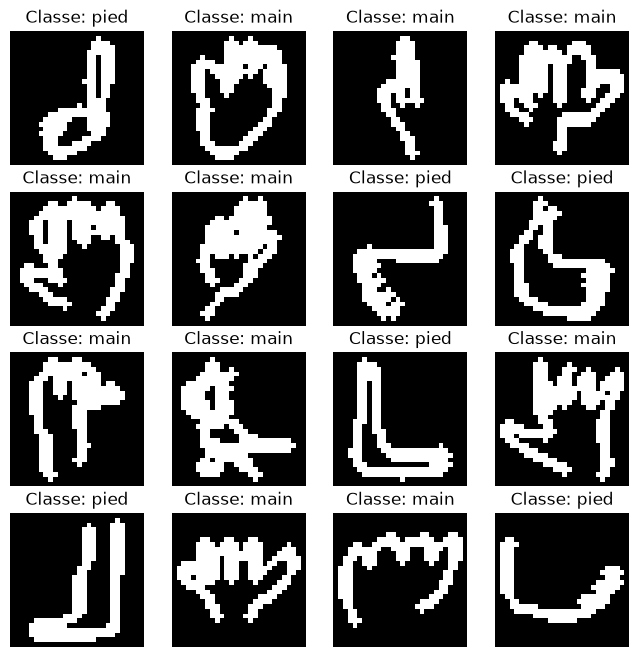

In [37]:
# TODO — afficher au moins 16 exemples de chaque classe
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
axes = axes.flatten()
for i in range(16): #affiche les 16 premiers images
    classe = 'main'
    if y[i] != 0 :
        classe = 'pied'
    axes[i].imshow(Ximg[i],cmap = 'grey')#plt.imshow est utilise pour afficher des images contrairement a plt.plot, ce qu'il fait : valeurs proche de 0 = noir, valeurs maximales(255) = blanc 
    axes[i].set_title(f"Classe: {classe}")
    axes[i].axis('off')
    
    


### 2.3 Images moyennes

Calculez $\bar x_0$, $\bar x_1$ et $\bar x_1-\bar x_0$. Commentez les zones qui différencient les classes.


Text(0.5, 1.0, 'Différence entre les images moyennes')

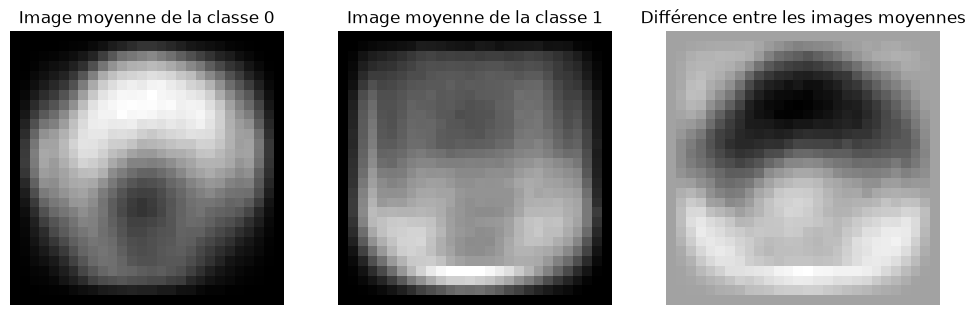

In [38]:
# TODO — images moyennes et différence
x_0 = [[0 for i in range(28)] for j in range(28)]
#x_0np = np.array(x_0) en toute rigeur
n_0 = 0
x_1 = [[0 for i in range(28)] for j in range(28)]
#x_1np = np.array(x_1)
n_1 = 0
fig , axe = plt.subplots(1,3,figsize = (12,4))
axes = axe.flatten()
for i,image in enumerate(Ximg):
    if y[i] == 0: #premiere classe
        x_0 +=image # on additionne les valeurs de la matrice terme a terme car image est un tableau numpy
        n_0 += 1 # Rq : pour des liste l1 + l1 = concatene, tableau numpy = somme terme a terme
    else:
        x_1 += image
        n_1 += 1
X_0 = x_0/n_0
X_1 = x_1/n_1
diff = X_1 - X_0 #idem car tableaux numpy
axes[0].imshow(X_0,cmap = 'gray')
axes[0].set_title("Image moyenne de la classe 0")
axes[0].axis('off')
axes[1].imshow(X_1,cmap = 'gray')
axes[1].axis('off')
axes[1].set_title("Image moyenne de la classe 1")
axes[2].imshow(diff,cmap = 'gray')
axes[2].axis('off')
axes[2].set_title("Différence entre les images moyennes")


### 2.4 Prétraitement et séparation apprentissage/test

Normalisez les pixels dans $[0,1]$, aplatissez chaque image en un vecteur de dimension 784 puis conservez 70 % des données pour l'apprentissage et 30 % pour le test.



In [39]:
# TODO
# TODO
X = []
max = 255
min = 0
for img in Ximg:
    img_norm = []
    for i in range(28):
        for j in range(28):
            img_norm.append((img[i][j] - min) / (max - min))
    X.append(img_norm)

def train_test_split(X,y,r=0.3):
    n = len(X)
    n_train = int(n*(1-r))
    X_train = X[:n_train]
    X_test = X[n_train:]
    y_train = y[:n_train]
    y_test = y[n_train:]
    return np.array(X_train), np.array(X_test), y_train, y_test

X_train, X_test, y_train, y_test = train_test_split(X,y,r=0.3)

print(X_train.shape, X_test.shape)


(1680, 784) (720, 784)


## 3. Construire le classifieur! 
On pose
$$
P(y=1\mid x)=\sigma(w^T x+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}.
$$

On absorbe le biais en ajoutant une colonne de 1 aux données via $\texttt{add\_bias}$.

### 3.1 Score linéaire et sigmoïde
Programmez $\texttt{sigmoid(z)}$ et tracez cette fonction.



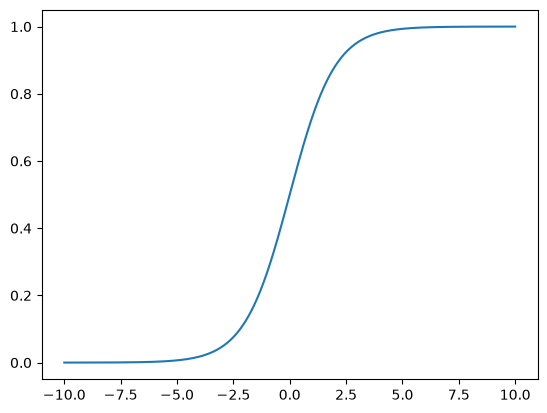

In [40]:
def add_bias(X):
    # TODO
    return np.column_stack([np.ones(X.shape[0]), X])


def sigmoid(z):
    # TODO 
    return 1 / (1 + np.exp(-z))


X_train_b = add_bias(X_train)
X_test_b = add_bias(X_test)
X = np.linspace(-10,10,1000)
plt.plot(X,sigmoid(X)) #que pour les tableaux numpy
plt.show()


### 3.2 Log-loss régularisée
Complétez le code.
    
$$
f(\theta)=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]
+\frac{\lambda}{2}\|w\|^2.
$$

Le biais n'est pas régularisé.

**Questions.** Quelle contribution donne une observation de classe $1$ lorsque le modèle prédit $p_i=0.99$ ? Et lorsque le modèle prédit $p_i=0.01$ ? Comparez qualitativement.

Lorseque $y_{i} = 1$ et $p_{i} = 1$ on a $y_i*\log(p_i)\approx 0$ ainsi la contribution est quasi nulle.Inversement losque $p_i = 0.01$ la contribution devient proche de $-\inf$ donc la penalité est très élevée.
Ainsi qualitativement, si le modèle est très confiant mais qu'il se trompe il est lourdement pénalisé.

**Question.** Pourquoi la log-loss pénalise-t-elle fortement une prédiction très confiante mais fausse ?

Pour apprendre que se tromper ne vient pas sans conséquence à la dure. C'est principalement due au fait que le log tendra vers -inf dans ce cas la.

**Question.** Quel est le rôle de $\lambda$ ? Que devrait devenir la norme de $w$ lorsque $\lambda$ augmente ?

Lambda est un hyperparamètre qu'on ajustera pour minimiser la log-loss et le bias 
Lorsque $\lambda$ augmente, le terme de régularisation $\frac{\lambda}{2}\Vert{}w\Vert{}^2$ pèse de plus en plus lourd dans le log-loss. Pour minimiser cette fonction, on doit donc réduire la norme de w.

**Question.** Pourquoi choisit-on ici de ne pas régulariser le biais $b$ ?

Le biais $b$ représente le seuil de décision global (le décalage de la frontière de classification), et non la sensibilité à une caractéristique particulière. Régulariser le biais pénaliserait le modèle pour avoir un décalage moyen non nul, ce qui l'empêcherait de s'ajuster correctement aux proportions globales des classes dans les données (sous-apprentissage). On ne régularise que les poids $w$ pour contrôler l'influence des caractéristiques.

### 3.3 Gradient
On veut montrer que, sans régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y), 
$$
et avec régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y)
+\lambda\begin{pmatrix}w\\0\end{pmatrix}.
$$

**Exercice.** Retrouvez les formules ci-dessus en utilisant $\sigma'(z)=\sigma(z)(1-\sigma(z))$.


Vérifiez soigneusement les dimensions de toutes les quantités dans l'expression matricielle du gradient.
Complétez le code ci-dessous.


In [41]:
def objective(theta, Xb, y, lmbda=1e-2):
    # TODO
    n = len(y) #Xb est le vecteur X avec add_bias (rajoute 1 sur la premier colonne)
    f = 0
    norme_w = 0
    for i in range(len(Xb)):
        p_i = sigmoid(np.transpose(theta @ Xb[i]))
        f += y[i]*np.log(p_i) + (1-y[i])*np.log(1-p_i)
    for i in range(len(theta)-1):
        norme_w += theta[i]**2
    f = -f/n + (lmbda/2)*(norme_w)
    return f

def grad_objective(theta, Xb, y, lmbda=1e-2):
    # TODO
    n = len(y)
    p = np.array([sigmoid(np.transpose(theta@Xb[i])) for i in range(len(Xb))])
    return (1/n)*(np.transpose(Xb)@(p-y)) + lmbda*np.concatenate([theta[:-1],[0]])
    # le slicing jusqu'a -1 veut dire qu'on prend tout les elements jusqu'a l'avant dernier, on ne prend pas le dernier element de theta car c'est le biais et on ne veut pas regulariser le biais



### 3.4 Vérification par différences finies

Comparez votre gradient à une approximation par différences centrées. Testez plusieurs valeurs de $h$ et commentez l'effet des erreurs d'arrondi.



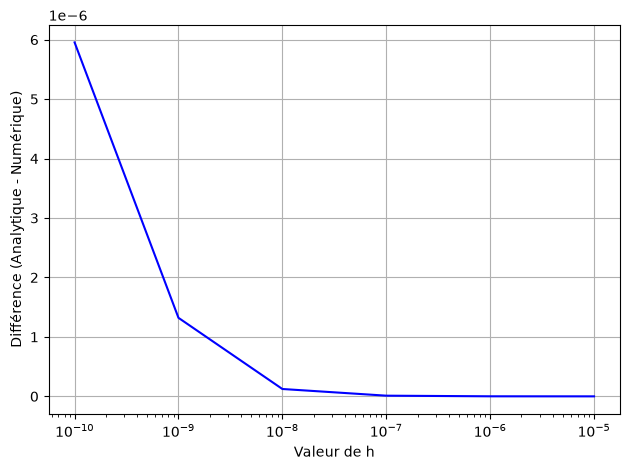

In [42]:
def finite_difference_gradient(f,Xb,y, theta, h=1e-6):
    g = np.zeros_like(theta, dtype=float)
    for j in range(theta.size):
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e,Xb,y) - f(theta - h*e,Xb,y)) / (2*h)
    return g

# Oui mais en dimension 785, vérifier toutes les composantes coûte cher.
# On peut vérifier un sous-ensemble d'indices tirés aléatoirement.
def finite_difference_gradient(f,Xb,y, theta, h=1e-6, indices=None):
   
    if indices is None:
        indices = np.arange(theta.size)
    g = np.full(theta.shape, np.nan, dtype=float)
    for j in indices:
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e,Xb,y) - f(theta - h*e,Xb,y)) / (2*h)
    return g




# TODO — comparer gradient analytique et gradient numérique

# Initialisation avec des petits poids aléatoires (entre -0.1 et 0.1)
theta = np.random.randn(785) * 0.01
#(je me suis aidee de l'IA pour le choix de theta car sinon on avait des log(0) je sais pas pourquoi)
grad_ana = grad_objective(theta, X_train_b, y_train)
H = np.array([1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5])
différences = []
indices_test = [0, 12, 100, 200, 300, 400, 500, 600, 700, 784]

for h in H:
    grad_num = finite_difference_gradient(objective, X_train_b, y_train, theta, h, indices=indices_test)
    
    #Compare avec la norme euclidienne
    diff = np.sum((grad_ana[indices_test] - grad_num[indices_test]) ** 2) ** 0.5
    différences.append(diff)

# Tracé
plt.plot(H, différences,color = 'blue')
plt.xscale('log')
plt.xlabel('Valeur de h')
plt.ylabel('Différence (Analytique - Numérique)')
plt.grid(True)
plt.tight_layout()
plt.show()






### 4. Optimiser la log-loss !!
#### Descente de gradient à pas fixe

On souhaite maintenant implémenter une descente de gradient à pas fixe: 
$$
\theta_{k+1}=\theta_k-\alpha\nabla f(\theta_k).
$$


Programmez une fonction $\texttt{gradient\_descent\_fixed}$ retournant: la solution, les valeurs de $f$, les normes du gradient et le nombre d'itérations.

Testez plusieurs pas et tracez $f(\theta_k)$ ainsi que $\|\nabla f(\theta_k)\|$.

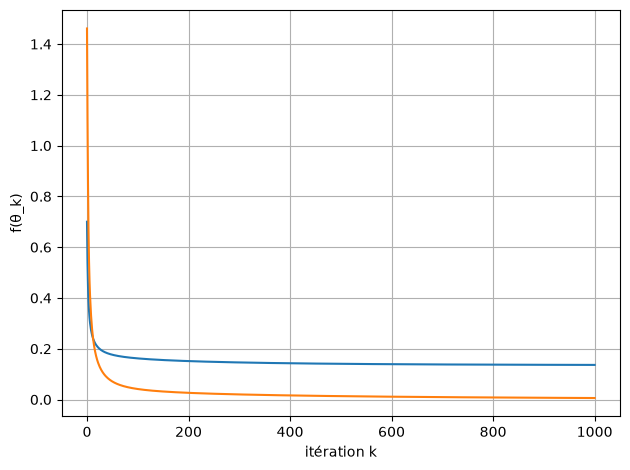

In [63]:
def gradient_descent_fixed(Xb, y, theta0, alpha, tol=1e-5, max_iter=1000):

    k = 0
    theta = [theta0]
    while k < max_iter and np.linalg.norm(grad_objective(theta[-1],Xb, y,)) > tol: #gradient non nul car sinon boucle infinie
        theta.append(theta[-1] - alpha * grad_objective(theta[-1],Xb, y,))
        k += 1
    return theta

theta0 = np.random.randn(785) * 0.01
alpha = 0.1
fk = [objective(t, X_train_b, y_train) for t in theta]
gk = [np.linalg.norm(grad_objective(t, X_train_b, y_train)) for t in theta]
n = len(fk)
X_f = [i for i in range(n)]
plt.plot(X_f, fk,color = 'red')
plt.plot(X_f, gk,color = 'blue')
plt.xlabel('itération k')
plt.ylabel('f(θ_k)')
plt.grid(True)
plt.tight_layout()
plt.show()

Tracez
    
$$
k\mapsto f(\theta_k),
\qquad
k\mapsto\|\nabla f(\theta_k)\|.
$$

Testez plusieurs valeurs de $\alpha$ sur le même point initial, par exemple $10^{-3}$, $10^{-2}$, $10^{-1}$, $0.5$, $1$, et $5$.


In [ ]:

# Quelques pas à comparer
fixed_results = {}
test = [0.01, 0.05, 0.1, 0.5,1.,2.]
for alpha in test:
    fixed_results[alpha] = (gradient_descent_fixed(X_train_b, y_train, theta0, alpha),[objective(t, X_train_b, y_train) for t in gradient_descent_fixed(X_train_b, y_train, theta0, alpha)])

for alpha in test:
    X,Y = fixed_results[alpha]
    plt.plot(X,Y,label=f'alpha={alpha}')

plt.xlabel('theta')
plt.ylabel('f(theta)')
plt.show()

KeyboardInterrupt: 

### 4.2 BONUS Règle d'Armijo

Pour $d_k=-\nabla f(\theta_k)$, on cherche $\alpha>0$ tel que
$$
f(\theta_k+\alpha d_k)
\leq
f(\theta_k)+c_1\alpha\nabla f(\theta_k)^\top d_k.
$$
Un backtracking part de $\alpha_0$ et remplace
$$
\alpha\leftarrow\rho\alpha,
\qquad 0<\rho<1,
$$
tant que la condition n'est pas satisfaite.

Programmez $\texttt{armijo\_step}$ puis une descente de gradient utilisant ce pas.



In [ ]:
def armijo_step(f, gradf, theta, d,
                alpha0=1.0, rho=0.5, c1=1e-4,
                min_alpha=1e-12, f0=None, g0=None):
    # TODO
    return alpha, n_eval


def gradient_descent_armijo(f, gradf, theta0,
                            tol=1e-5, max_iter=1000,
                            alpha0=1.0, rho=0.5, c1=1e-4):
    # TODO
    return {
        "theta": theta, "f": np.array(hist_f), "grad_norm": np.array(hist_g),
        "alpha": np.array(hist_a), "iterations": k,
        "n_f_eval": n_f_eval, "time": elapsed
    }

    


### 4.3 BONUS Comparaison numérique
Comparez pas fixe et Armijo selon :
- nombre d'itérations ;
- nombre d'évaluations de $f$ ;
- temps CPU ;
- valeur finale de $f$ ;
- norme finale du gradient.


In [ ]:
lmbda = 1e-2
f_train = lambda th: objective(th, X_train_b, y_train, lmbda)
g_train = lambda th: grad_objective(th, X_train_b, y_train, lmbda)
theta0 = np.zeros(X_train_b.shape[1])


# Quelques pas à comparer. 
fixed_results = {}
for alpha in [0.01, 0.05, 0.1, 0.5]:
    fixed_results[alpha] = gradient_descent_fixed(
        objective,
        grad_objective,
        X_train_b,
        y_train,
        theta0,
        alpha=alpha,
        lda=lmbda,
        tol=1e-4,
        max_iter=500
    )

armijo_result = gradient_descent_armijo(
    f_train, g_train, theta0, tol=1e-4, max_iter=500
)

# TODO: plot f for fixed alpha and armijo

for alpha, res in fixed_results.items():
    #TODO print performances

_IncompleteInputError: incomplete input (4184744656.py, line 29)

## Avant l'évaluation du modèle, on retient le meilleur parametre $\theta^*$

In [ ]:
theta_star = ... #optimal parameter!


## 5. Évaluer et interpréter !!!
Calculez les probabilités et les classes sur le jeu de test, puis l'accuracy, la précision, le rappel et la matrice de confusion.



In [ ]:
def predict_proba(theta, Xb):
    # TODO
    ...


def predict(theta, Xb, threshold=0.5):
    # TODO
    ...

# TODO — métriques sur le test


Accuracy : 0.9319444444444445
Precision (classe 1) : 0.9331476323119777
Recall (classe 1) : 0.9305555555555556
Log-loss : 0.1824911917491751
Matrice de confusion :
[[336  24]
 [ 25 335]]


### 5.2 Dessins mals classés

Affichez plusieurs dessins mal classés et les dessins dont la probabilité est la plus proche de $0.5$. 

Cherchez aussi un cas où le modèle se trompe avec une forte confiance.


In [ ]:
def show_indices(indices, title, max_n=12):
    indices = np.asarray(indices)[:max_n]
    n = len(indices)
    if n == 0:
        print(title, ": aucun exemple")
        return
    cols = 4
    rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.5*rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(X_test[i].reshape(28,28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"vrai={class_names[y_test[i]]}\np({class_names[1]})={p_test[i]:.3f}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()

wrong = np.where(y_pred != y_test)[0]
show_indices(wrong, "Exemples mal classés")

ambiguous = np.argsort(np.abs(p_test - 0.5))
show_indices(ambiguous, "Dessins les plus ambigus")

if len(wrong):
    confident_wrong = wrong[np.argsort(-np.abs(p_test[wrong]-0.5))]
    show_indices(confident_wrong, "Erreurs les plus confiantes")


### 5.3 Visualiser le vecteur $w$
Remettez $w\in\mathbb{R}^{784}$ sous forme d'une image $28\times28$. Les coefficients positifs favorisent la classe 1, les négatifs la classe 0. Comparez cette carte à $\bar x_1-\bar x_0$.


In [ ]:
w = ...
fig, axes = plt.subplots(...)


### 5.4 Comparaison à sklearn

utilisez `LogisticRegression` comme référence et comparez les performances. Les conventions de régularisation peuvent différer.


In [ ]:
from sklearn.linear_model import LogisticRegression


## 6. Défi — dessinez vous-même avec Qt

L'objectif est maintenant de tester le classifieur sur **vos propres dessins**.

Cette dernière partie reprend l'architecture du TP 2 :

- **`dessin_process.py`** contient les fonctions qui manipulent les tableaux NumPy ;
- **`dessin_viewer.py`** contient l'interface Qt et les interactions utilisateur ;

Les fonctions `paint_disk` et `paint_segment`, définies dans `dessin_process.py`,
sont à nouveau utilisées par `DrawingCanvas` dans `dessin_viewer.py` lorsqu'un utilisateur dessine à la souris.

#### Interface Qt

La fenêtre contient trois boutons :

- **Effacer** : remet le bitmap à zéro ;
- **Classifier** : appelle le classifieur défini dans le notebook ;
- **Sauver** : ouvre une boîte de dialogue Qt et enregistre le dessin en PNG.

L'interface ne connaît pas la régression logistique. Le notebook lui fournit une
fonction `classify_callback`.
Elle effectue le
prétraitement puis affiche la probabilité
\[
P(y=1\mid x)
\]
et la classe prédite.

Le modèle a été entraîné sur des images QuickDraw centrées et ramenées à
\(28\times 28\). Il faut donc appliquer **le même principe de prétraitement**
à un dessin personnel avant de le classer :

\[
\text{dessin personnel}
\longrightarrow
\text{détection de la zone dessinée}
\longrightarrow
\text{redimensionnement + recentrage}
\longrightarrow
28\times 28
\longrightarrow
\text{régression logistique}.
\]

La fonction `prepare_for_model` ci-dessous réutilise la fonction
`compute_centering_parameters` déjà employée dans `image_converter`.
Ainsi, les dessins QuickDraw et vos dessins personnels suivent la même
convention géométrique.
Si le chargement ne fonctionnement, il est possible de **dessiner dans un autre logiciel**, d'enregistrer le dessin en PNG, puis de
   le charger avec `load_png_as_bitmap` (du module `dessin_process`).
   
Vous devez tester au moins :

1. un dessin naturel de chaque classe ;
2. un dessin très minimaliste ;
3. un dessin volontairement ambigu ;
4. un dessin destiné à tromper le modèle avec une forte confiance.

Analysez chaque résultat : le dessin est-il correctement classé ? La
probabilité est-elle cohérente avec votre propre niveau d'hésitation ?


#### 6.1 importer prepare_for_model depuis le module `dessin_process` et compléter $\texttt{classify\_my\_bitmap}$ ci-dessous ainsi que $\texttt{\_paint\_at}$ depuis le module `dessin_viewer`

In [ ]:
def classify_my_bitmap(arr, theta=theta_star):
    """
    Classe un dessin personnel et affiche :
    - le dessin original ;
    - l'image 28 x 28 réellement donnée au modèle.
    """

    # -------------------------------------------------------------
    # 1. Prétraitement
    # -------------------------------------------------------------
    img28 = prepare_for_model(arr)

    # -------------------------------------------------------------
    # 2. Mise sous la forme attendue par le classifieur
    # -------------------------------------------------------------
    xb = add_bias(img28.reshape(1, -1))

    # -------------------------------------------------------------
    # 3. Probabilité et prédiction
    # -------------------------------------------------------------
    p = float(...) #TODO!
    pred = int(p >= 0.5)

    # -------------------------------------------------------------
    # 4. Visualisation :
    #    dessin original / image vue par le modèle
    # -------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

    axes[0].imshow(
        arr,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0].set_title(
        "Ce que vous avez dessiné"
    )
    axes[0].axis("off")

    axes[1].imshow(
        img28,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    axes[1].set_title(
        "Ce que voit le modèle"
    )
    axes[1].axis("off")

    fig.suptitle(
        f"Prédiction : {class_names[pred]} "
        f"— P({class_names[1]}) = {p:.3f}"
    )

    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # 5. Informations renvoyées à l'interface Qt
    # -------------------------------------------------------------
    return {
        "label": class_names[pred],
        "probability": p,
        "class1_name": class_names[1],
    }

In [ ]:
# ================================================================
# OUVRIR LA FENÊTRE QT
# ================================================================
# La commande %gui qt5 a été exécutée dans la cellule des imports.
# show_draw() crée la fenêtre, l'affiche et conserve QApplication.
#
# IMPORTANT : on conserve la fenêtre dans la variable pad afin qu'elle
# ne soit pas détruite par le ramasse-miettes Python.

pad = show_draw(
    size=280,
    brush=7,
    classify_callback=classify_my_bitmap,
    title=f"QuickDraw — {class_names[0]} / {class_names[1]}",
)


### Variante : charger un dessin PNG

Si le canevas interactif ne fonctionne pas :

1. dessinez l'objet sur un fond blanc ou noir ;
2. enregistrez-le au format PNG dans le dossier du notebook ;
3. chargez le fichier avec `load_png_as_bitmap` ;
4. envoyez le tableau obtenu à `classify_my_bitmap`.

`load_png_as_bitmap` **ne recentre pas** l'image : elle se contente de
la lire et de mettre les traits en blanc sur fond noir. Le recentrage est
effectué une seule fois, dans `prepare_for_model`, au moment de la
classification.


In [ ]:
# Exemple avec une image externe :
# my_img = load_png_as_bitmap("mon_dessin.png")
# classify_my_bitmap(my_img)

### 6.1 Bilan

Revenez à votre réponse de la Question préambule section 1,
après avoir comparé avec les autres groupes vos accuracies et types d'erreurs. 
**Question**  Quel couple semble le mieux séparé par un modèle linéaire ?
